In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
files = [
    "../data/prices_round_1_day_-2.csv",
    "../data/prices_round_1_day_-1.csv",
    "../data/prices_round_1_day_0.csv",
]

datasets = {}

for file in files:
    df = pd.read_csv(file, sep=";")
    day = df["day"].iloc[0]
    datasets[day] = df


PRODUCT INTARIAN_PEPPER_ROOT | DAY -2
count     9984.000000
mean     10499.963542
std        288.722378
min       9998.500000
25%      10250.000000
50%      10500.000000
75%      10750.000000
max      11003.000000
Name: mid_price, dtype: float64


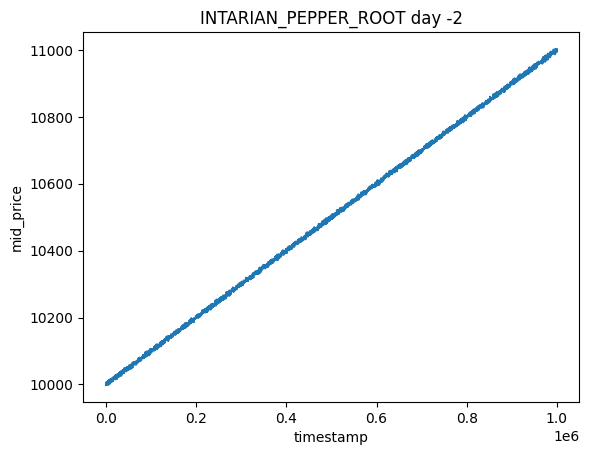


PRODUCT INTARIAN_PEPPER_ROOT | DAY -1
count     9983.000000
mean     11500.030051
std        288.669011
min      10995.000000
25%      11250.750000
50%      11500.000000
75%      11750.000000
max      12006.000000
Name: mid_price, dtype: float64


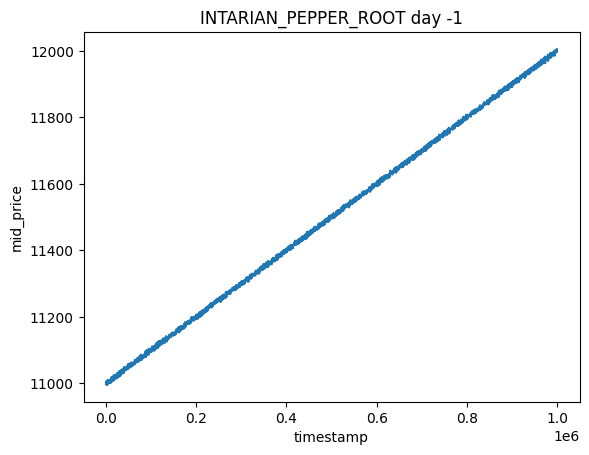


PRODUCT INTARIAN_PEPPER_ROOT | DAY 0
count     9979.000000
mean     12500.173013
std        288.730986
min      11994.000000
25%      12250.000000
50%      12500.000000
75%      12750.500000
max      13007.000000
Name: mid_price, dtype: float64


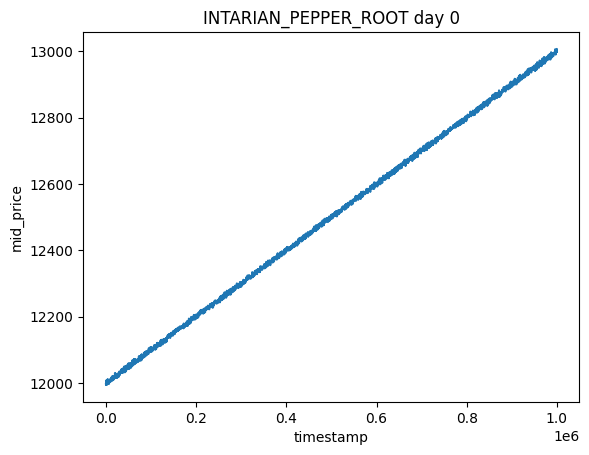

In [3]:
products = ["INTARIAN_PEPPER_ROOT"]

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        print(f"\nPRODUCT {product} | DAY {day}")
        print(df_p["mid_price"].describe())

        plt.figure()
        plt.plot(df_p["timestamp"], df_p["mid_price"])
        plt.title(f"{product} day {day}")
        plt.xlabel("timestamp")
        plt.ylabel("mid_price")
        plt.show()

In [4]:
summary_rows = []

for product in products:
    for day, df in datasets.items():
        df_p = df[df["product"] == product].copy()
        df_p = df_p[df_p["mid_price"] > 0]

        summary_rows.append({
            "product": product,
            "day": day,
            "count": df_p["mid_price"].count(),
            "mean": df_p["mid_price"].mean(),
            "median": df_p["mid_price"].median(),
            "std": df_p["mid_price"].std(),
            "min": df_p["mid_price"].min(),
            "max": df_p["mid_price"].max(),
        })

summary_df = pd.DataFrame(summary_rows).sort_values(["product", "day"])
summary_df

,product,day,count,mean,median,std,min,max
0,INTARIAN_PEPPER_ROOT,-2,9984,10499.963542,10500.0,288.722378,9998.5,11003.0
1,INTARIAN_PEPPER_ROOT,-1,9983,11500.030051,11500.0,288.669011,10995.0,12006.0
2,INTARIAN_PEPPER_ROOT,0,9979,12500.173013,12500.0,288.730986,11994.0,13007.0
